# Поиск оптимальной стратегии методом ExpectedSARSA

Реализуем поиск оптимальной стратегии по TD методу ExpectedSARSA с обобщённой итерацией по $\varepsilon$-жадным стратегиям. Для этого сформируем потомка абстрактного класса "табличного" агента.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
import pickle

from abc import ABC, abstractmethod
from collections import defaultdict


class QTableAgent(ABC):
    def __init__(self, env, eps = 0.1, alpha = 0.1):
        self.nA = env.action_space.n # число действий
        self.N = defaultdict(lambda: np.zeros(self.nA))
        # заполняемая таблица значений Q-функции, хранящая ценности пар состояние-действие
        self.Q = defaultdict(lambda: np.zeros(self.nA))
    
        self.eps = eps   
        self.alpha = alpha

    # выбор eps-жадного действия        
    def reset(self):
        self.N = defaultdict(lambda: np.zeros(self.nA))
        self.Q = defaultdict(lambda: np.zeros(self.nA))

    # выбор eps-жадного действия        
    def get_action(self, state):
        if np.random.rand() < self.eps:
            return np.random.choice(self.nA)
        return self.best_action(state)
    
    # выбор жадного действия        
    def best_action(self, state):
        return np.argmax(self.Q[state])

    def get_Q(self, state, act):
        return self.Q[state][act]

    def update_Q(self, state, act, goal):
        # обновление оценки по методу выборочного среднего или с постоянным шагом обновления
        if self.alpha is None:
            self.N[state][act] += 1
            self.Q[state][act] += (goal - self.Q[state][act])/self.N[state][act]
        else:
            self.Q[state][act] += self.alpha*(goal - self.Q[state][act])

    @abstractmethod
    def learn(self):
        """Метод обучения"""
        pass

    def play(self, env, n_episodes):
        """Оценка качества обученного агента. """
        for _ in tqdm(range(n_episodes)):
            state, _ = env.reset()
            while True:
                # выбираем лучшие действия
                action = self.best_action(state)
                state, reward, terminated, truncated, _ = env.step(action)
                if terminated or truncated:
                    break

    def save_Q(self, name):
        os.makedirs('savedModels', exist_ok=True)
        with open('savedModels/TableAgent_'+name+".pkl",'wb') as f:
            pickle.dump(dict(self.Q), f)
        return 'savedModels/TableAgent_'+name+".pkl"
        
    def load_Q(self, name):
        self.reset()
        with open(name, 'rb') as f:
            loaded_data = pickle.load(f)
            self.Q = defaultdict(lambda: np.zeros(self.nA), loaded_data) 

### Задача

Требуется написать метод `learn()` для агента `ExpSARSA_Agent` для обучения по методу ExpectedSARSA, как метода обучения
с единой стратегией с обобщённой итерацией по $\varepsilon$-жадным стратегиям (см. псевдокод в слайдах).

In [7]:
from dataclasses import dataclass

@dataclass
class ConfigTD:
    gamma: float = 0.99
    eps_start: float = 1.0
    eps_decay: float = 0.999
    eps_min: float = 0.01
    alpha_start: float = 0.1
    alpha_decay: float = 0.99
    alpha_min: float = 0.05

class ExpSARSA_Agent(QTableAgent): 
    def __init__(self, env, config = None):
        super().__init__(env)
        if config is None:
            self.config = ConfigTD()
        else:
            self.config = config
            
        self.env = env
        self.alpha = self.config.alpha_start
        self.eps = self.config.eps_start
        self.gamma = self.config.gamma

    def learn(self, n_episodes = 1000, restart = True):
        if restart == True:
            self.alpha = self.config.alpha_start
            self.eps = self.config.eps_start 
            self.reset()

        # ===== дописать шаги алгоритма обучения  =====
        for i in tqdm(range(n_episodes)):
        # запускаем эпизод взаимодействия со средой
            #===== ???? =====
                
            # уменьшение доли шагов исследования
            self.eps = max(self.eps * self.config.eps_decay, self.config.eps_min)         
            if self.alpha is not None:
                self.alpha = max(self.alpha * self.config.alpha_decay, self.config.alpha_min)   

### Пример 1

Рассмотрим снова задачу о клеточном мире с утёсом `CliffWalking-v1` и найдём оптимальную стратегию методом ExpectedSARSA.

In [4]:
import gymnasium as gym
# Создание среды
env = gym.make('CliffWalking-v1')
n_episodes = 1000
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

config = ConfigTD(gamma = 0.99,
                eps_start = 0.5, 
                eps_decay = 0.99, 
                eps_min = 0.001,                
                alpha_start = 0.25, 
                alpha_decay = 1.0, 
               )

# создание табличного агента
agent = ExpSARSA_Agent(env, config)

# обучение агента и получение доходов по эпизодам
agent.learn(n_episodes = n_episodes)

100%|██████████| 1000/1000 [00:00<00:00, 1271.81it/s]


Выведем график доходов за эпизоды, полученных в взаимодействия агента со средой.

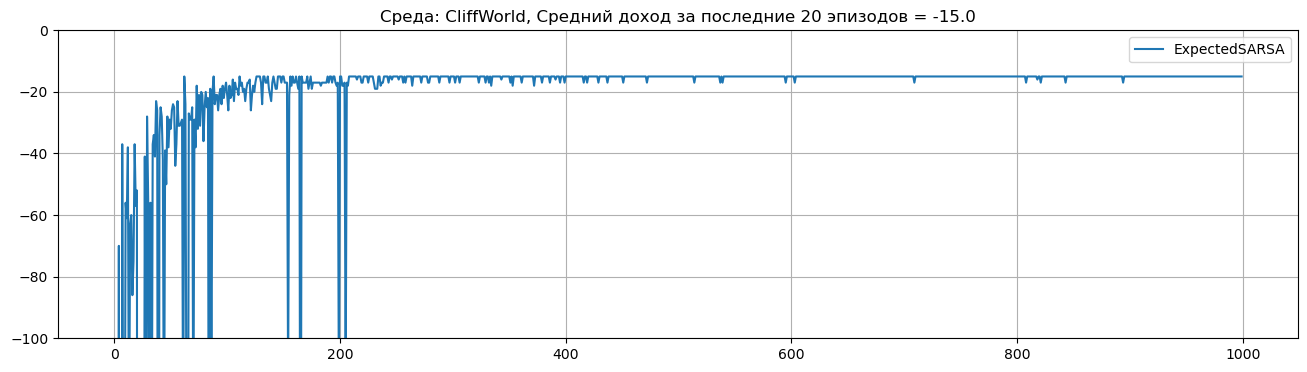

In [5]:
import matplotlib.pyplot as plt
# для того, чтобы избежать ошибок при построении графиков
#import os
#os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

# в названии графика среднее вознаграждение за 20 последних эпизодов
def plot_rewards(env_name, returns, label):
    fig = plt.figure(figsize=(16, 4))
    plt.title("Среда: "+env_name+", Средний доход за последние 20 эпизодов = "+str(np.mean(returns[-20:])))
    plt.plot(returns, label=label)
    plt.grid()
    plt.legend()
    plt.ylim(-100, 0)
    plt.show()
    
# график доходов
returns = np.array(env.return_queue)
plot_rewards("CliffWorld", returns, 'ExpectedSARSA')

График доходов по эпизодам показывает, что уже к 300 эпизоду агент достиг фиксированной стратегии. Можно отметить, что разброс значений чуть ниже, чем у SARSA и Q-обучения. 

Общий доход не оптимален, хотя лучше чем у SARSA. Рассмотрим стратегию, которой обучился агент.

In [6]:
import time
from IPython.display import clear_output

env = gym.make("CliffWalking-v1", render_mode='ansi')
env = gym.wrappers.RecordEpisodeStatistics(env)

state, _ = env.reset()
print(env.render())

while True:
    state, reward, terminated, truncated, _ = env.step(agent.best_action(state)) 
    
    time.sleep(.2)
    clear_output(wait=True)
    print(env.render())

    if terminated or truncated:
        break

print(env.return_queue[-1])
env.close()

o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  C  C  C  C  C  C  C  C  C  C  x


-15.0


Стратегия, которой обучился агент, является в некотором смысле средней между стратегиями, полученными по методам SARSA и Q-обучением. В данном случае мы использовали  Expected SARSA как метод с единой стратегией, то есть одна и та же eps-жадная стратегия используется как для исследования, так и для обновления. Но благодаря выбору математического ожидания вместо одного значения, результат обучения лучше чем у SARSA, то есть агент обнаружил, что по средней линии идти достаточно безопасно.

### Пример 2

Применим метод ExpectedSARSA для решения задачи о такси `Taxi-v3`.

In [7]:
import gymnasium as gym

# Создание среды
env = gym.make('Taxi-v4')
n_episodes = 5000
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

config = ConfigTD(gamma = 0.99,
                eps_start = 1.0, 
                eps_decay = 0.99, 
                eps_min = 0.01,                
                alpha_start = 0.2, 
                alpha_decay = 1.0, 
               )

# создание табличного агента
agent = ExpSARSA_Agent(env, config)

# обучение агента и получение доходов по эпизодам
agent.learn(n_episodes = n_episodes)

100%|██████████| 5000/5000 [00:05<00:00, 896.84it/s] 


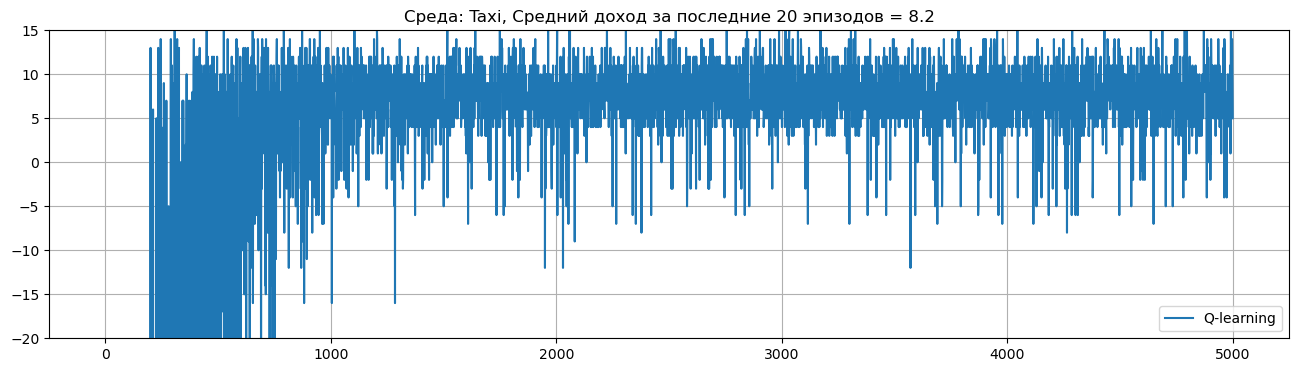

In [8]:
# в названии графика среднее вознаграждение за 20 последних эпизодов
def plot_rewards(env_name, returns, label):
    fig = plt.figure(figsize=(16, 4))
    plt.title("Среда: "+env_name+", Средний доход за последние 20 эпизодов = "+str(np.mean(returns[-20:])))
    plt.plot(returns, label=label)
    plt.grid()
    plt.legend()
    plt.ylim(-20, 15)
    plt.show()

returns = np.array(env.return_queue)
plot_rewards("Taxi", returns, 'Q-learning')

График вознаграждений выводится для фактически полученных вознаграждений из траекторий, генерируемых по eps-жадной стратегии. Если выбирать действия жадно, относительно обученной Q-функции, то агент уже обучился оптимальной стратегии действий. В этом можно убедиться в симуляции.

In [15]:
n_episodes = 10000
env = gym.make("Taxi-v4")
env = gym.wrappers.RecordEpisodeStatistics(env, buffer_length=n_episodes)

agent.play(env, n_episodes)

100%|██████████| 10000/10000 [00:02<00:00, 3654.83it/s]


Средний доход за эпизод равен: 7.9456
Минимальный доход за эпизод равен: 3.0
Максимальный доход за эпизод равен: 15.0


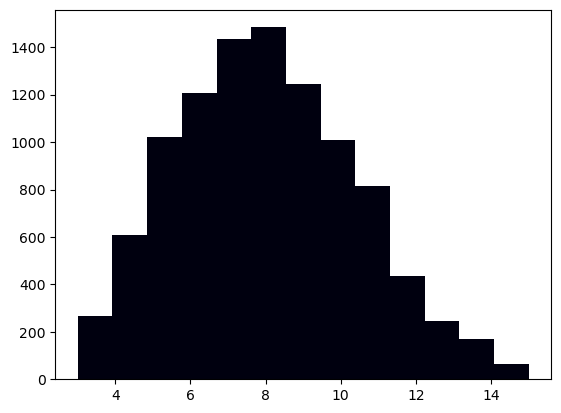

In [16]:
print('Средний доход за эпизод равен:', np.mean(env.return_queue))
print('Минимальный доход за эпизод равен:', np.min(env.return_queue))
print('Максимальный доход за эпизод равен:', np.max(env.return_queue))

import matplotlib.pyplot as plt
plt.hist(env.return_queue, bins=13, color='#00000f')
plt.show()